# Quantum Execution Integrity Challenge: Group 07 solution notebook

This notebook presents our solution to both scored stages and summarises the optional bonus. It is a
companion to the required submission, not a replacement for it:

* **`solve.py`** contains the forensic analysis (`solve_stage1`, `solve_stage2`).
* **`outputs/result.json`** was generated from that exact `solve.py` by `evaluate.py`.
* **`extensions/`** holds the bonus work (B1 Quantum Metal, B2 scqubits, B3 QuTiP).

**Conventions**
- Markdown cells contain explanation only. Every concrete value is printed by a code cell, either from the live
  output of `solve.py` or read directly from the frozen artifacts in `stages/*/artifacts/`.
- The notebook writes no files: bytecode caching is disabled and no artifact or `result.json` is modified.
- It is deterministic. Simulation results are read from `solve.py`, which uses fixed seeds.

## Contents and rubric map

| Section | Stage 1 milestones | Stage 2 milestones |
|---|---|---|
| [0. Setup and integrity](#0.-Setup-and-integrity) | | |
| [1.1 Circuits](#1.1-Intended-vs-compiled-circuit) | M2 | |
| [1.2 Mapping and schedule](#1.2-Mapping-and-schedule) | M3, M4 | |
| [1.3 Control/calibration provenance](#1.3-Control-and-calibration-provenance) | M5 | |
| [1.4 Execution evidence and diagnostics](#1.4-Execution-evidence-and-diagnostics) | M10 | |
| [1.5 Verdict and resources](#1.5-Verdict,-affected-operation-and-resources) | M1, M6, M7, M8 | |
| [1.6 Incidental anomalies](#1.6-Incidental-anomalies-(rejected)) | M9 | |
| [1.7 Repair and validation](#1.7-Repair-and-repair-validation) | M11, M12 | |
| [2.1 Circuit, mapping, runtime](#2.1-Circuit,-compilation,-mapping-and-runtime) | | M2, M3 |
| [2.2 Design and model provenance](#2.2-Device-design-and-device-model-provenance) | | M4, M5 |
| [2.3 Physical consequence](#2.3-Coupling/rate-physical-consequence) | | M6 |
| [2.4 Structured simulation](#2.4-Structured-simulation-of-the-32-qubit-workload) | | M6 (support) |
| [2.5 Boundary and verdict](#2.5-Root-cause-boundary-and-verdict) | | M1, M7 |
| [2.6 Alternatives](#2.6-Rejected-alternatives-and-distractors) | | M8 |
| [2.7 Repair and validation](#2.7-Repair-and-repair-validation) | | M9, M10 |
| [3. Bonus](#3.-Bonus-summary-(extensions/)) / [4. Reproduce](#4.-Reproducing-everything) | | |

## 0. Setup and integrity

In [1]:
import sys, os, json, math, textwrap, importlib.util, subprocess, platform
sys.dont_write_bytecode = True            # do not create __pycache__ anywhere (including artifact folders)
from pathlib import Path
import numpy as np, scipy, matplotlib
import matplotlib.pyplot as plt

def find_root():
    env = os.environ.get('QEIC_ROOT')
    for p in ([Path(env)] if env else []) + [Path.cwd(), *Path.cwd().parents]:
        if (p / 'solve.py').exists() and (p / 'stages').is_dir():
            return p.resolve()
    raise RuntimeError('Repository root not found: open this notebook inside the repository or set QEIC_ROOT.')
ROOT = find_root()
S1, S2, E = ROOT / 'stages/stage_1/artifacts', ROOT / 'stages/stage_2/artifacts', ROOT / 'extensions'
J = lambda d, n: json.loads((d / n).read_text(encoding='utf-8'))
spec = importlib.util.spec_from_file_location('solve', ROOT / 'solve.py')
solve = importlib.util.module_from_spec(spec); spec.loader.exec_module(solve)

def say(label, text, width=110):
    print(textwrap.fill(f'{label}: {text}', width=width, subsequent_indent='    '))
def items(label, xs, width=110):
    print(f'{label}:')
    for x in xs:
        print(textwrap.fill(str(x), width=width, initial_indent='  - ', subsequent_indent='    '))
def evidence(xs):
    for e in xs:
        print(textwrap.fill(f"[{e['artifact']}{' @ ' + e['locator'] if e.get('locator') else ''}] {e['claim']}",
                            width=110, initial_indent='  - ', subsequent_indent='    '))

import qiskit, qiskit_aer
print('repo root:', ROOT)
print(f"python {platform.python_version()} | qiskit {qiskit.__version__} | qiskit-aer {qiskit_aer.__version__} | "
      f"numpy {np.__version__} | scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")

repo root: /home/user/csaw-qeic-group-07
python 3.13.18 | qiskit 2.6.2 | qiskit-aer 0.18.2 | numpy 2.5.4 | scipy 1.18.1 | matplotlib 3.11.2


In [2]:
# 1) the submitted result is structurally valid and was generated from this exact solve.py (hash check)
r = subprocess.run([sys.executable, '-B', 'validate_submission.py', 'outputs/result.json', '--submission', 'solve.py'],
                   cwd=ROOT, capture_output=True, text=True)
print('validator:', (r.stdout or r.stderr).strip())
# 2) run the solver live and compare every field with the stored result
s1, s2 = solve.solve_stage1(S1), solve.solve_stage2(S2)
stored = J(ROOT / 'outputs', 'result.json')['stage_submissions']
for name, live in (('stage_1', s1), ('stage_2', s2)):
    print(f'{name}: live solve.py output identical to outputs/result.json (all fields): '
          f'{stored[name] == json.loads(json.dumps(live))}')
print()
for name, s in (('Stage 1', s1), ('Stage 2', s2)):
    say(name, f"{s['verdict']} (confidence {s['confidence']}) - {s['suspected_fault_type']}")

validator: submission structurally valid; final correctness scoring is organizer-side


stage_1: live solve.py output identical to outputs/result.json (all fields): True
stage_2: live solve.py output identical to outputs/result.json (all fields): True

Stage 1: INTEGRITY_VIOLATION (confidence 0.95) - STALE_CONTROL_BINDING_WRONG_PHYSICAL_EDGE (calibration
    provenance / epoch mismatch)
Stage 2: INTEGRITY_VIOLATION (confidence 0.95) - STALE_DEVICE_MODEL_PROVENANCE -> COUPLING_MISCALIBRATION
    (coherent RZZ over-rotation)


# Stage 1: execution-stack forensics

**Question.** Did the small GHZ job execute what was requested? We trace each layer in turn: intended →
compiled → mapping → schedule → control binding → calibration profile → physical qubits → counts.

## 1.1 Intended vs compiled circuit

In [3]:
from qiskit import qpy
def instrs(c):
    return [(i.operation.name, [c.find_bit(q).index for q in i.qubits], [round(float(p), 6) for p in i.operation.params],
             [c.find_bit(b).index for b in i.clbits]) for i in c.data]
with open(S1 / 'intended_circuit.qpy', 'rb') as f: ci = qpy.load(f)[0]
with open(S1 / 'compiled_circuit.qpy', 'rb') as f: cc = qpy.load(f)[0]
print(f"{'#':>2} {'intended':32s} {'compiled':32s}")
for k, (a, b) in enumerate(zip(instrs(ci), instrs(cc))):
    print(f"{k:>2} {a[0]+' q'+str(a[1])+' '+str(a[2])+(' -> c'+str(a[3]) if a[3] else ''):32s} "
          f"{b[0]+' phys'+str(b[1])+' '+str(b[2])+(' -> c'+str(b[3]) if b[3] else ''):32s}")
print(); say('compiler (M2)', s1['layer_assessments']['compiler'])

 # intended                         compiled                        
 0 rz q[0] [1.570796]               rz phys[0] [1.570796]           
 1 sx q[0] []                       sx phys[0] []                   
 2 rz q[0] [1.570796]               rz phys[0] [1.570796]           
 3 cx q[0, 1] []                    cx phys[0, 1] []                
 4 cx q[1, 2] []                    cx phys[1, 4] []                
 5 measure q[0] [] -> c[0]          measure phys[0] [] -> c[0]      
 6 measure q[1] [] -> c[1]          measure phys[1] [] -> c[1]      
 7 measure q[2] [] -> c[2]          measure phys[4] [] -> c[2]      

compiler (M2): CONSISTENT. All 8 compiled instructions equal the intended ones with qubits relabelled by
    mapping M2 (q0->0, q1->1, q2->4); gate names, RZ parameters and clbit targets unchanged; no gates added or
    removed.


## 1.2 Mapping and schedule

In [4]:
mc, mh = J(S1, 'mapping_current.json'), J(S1, 'mapping_history.json')
sch, log = J(S1, 'schedule.json'), J(S1, 'execution_log.json')
for m in mh['mappings']:
    print(f"mapping {m['mapping_id']}: {m['logical_to_physical']}  from {m['effective_from']}  "
          f"until {m.get('effective_until', '-')}  ticket {m.get('change_ticket', '-')}")
print(f"current mapping record: {mc['mapping_id']} {mc['logical_to_physical']} | schedule mapping_id: {sch['mapping_id']} "
      f"| execution_log mapping_id: {log['mapping_id']}")
print('\nschedule (ns):')
for o in sch['operations']:
    print(f"  {o['id']:8s} {o['gate']:8s} phys {str(o['physical_qubits']):7s} start {o['start']:>4} dur {o['duration']:>4}"
          f"  {o.get('logical_operation', '')} {o.get('control_binding', '')}")
print()
say('mapping (M3)', s1['layer_assessments']['mapping']); print()
say('scheduling (M4)', s1['layer_assessments']['scheduling'])

mapping M1: {'q0': 0, 'q1': 1, 'q2': 2}  from 2026-05-02T12:00:00Z  until 2026-08-14T09:00:00Z  ticket -
mapping M2: {'q0': 0, 'q1': 1, 'q2': 4}  from 2026-08-14T09:00:00Z  until -  ticket maint_2048
current mapping record: M2 {'q0': 0, 'q1': 1, 'q2': 4} | schedule mapping_id: M2 | execution_log mapping_id: M2

schedule (ns):
  prep_0a  rz       phys [0]     start    0 dur    0   
  prep_0b  sx       phys [0]     start    0 dur   32   
  prep_0c  rz       phys [0]     start   32 dur    0   
  ent_41   cx       phys [0, 1]  start   40 dur  176  cx_0_1 bind_41
  ent_73   cx       phys [1, 4]  start  224 dur  192  cx_1_2 bind_73
  read_0   measure  phys [0]     start  432 dur  720   
  read_1   measure  phys [1]     start  432 dur  720   
  read_2   measure  phys [4]     start  432 dur  720   

mapping (M3): CONSISTENT. M2 agrees with mapping_history, the compiled circuit layout, the schedule and the
    execution log; device epoch D20 matches the backend. It replaced M1 at 2026-08-14T09:

## 1.3 Control and calibration provenance

Each two-qubit gate is followed from its schedule entry through its control binding to its calibration profile,
and then to the physical qubits that profile actually drives (via `backend.json` `endpoint_registry`). Below
that, the provenance timeline is assembled from every timestamp in the artifacts.

In [5]:
be = J(S1, 'backend.json'); n2p = {k: v['physical_index'] for k, v in be['endpoint_registry'].items()}
man, cur, prev = J(S1, 'control_manifest.json'), J(S1, 'calibration_current.json'), J(S1, 'calibration_previous.json')
profiles = {p['profile_id']: dict(p, epoch=c['calibration_epoch'], dev=c['device_epoch']) for c in (prev, cur) for p in c['profiles']}
print(f"job calibration epoch (execution_log): {log['calibration_epoch']} | manifest device epoch: {man['device_epoch']}")
print(f"{'op':8s} {'scheduled on':12s} {'binding':8s} {'epoch':5s} {'profile':7s} {'chan':4s} {'drives':7s} result")
for b in man['bindings']:
    op = next(o for o in sch['operations'] if o.get('control_binding') == b['binding_id'])
    p = profiles[b['calibration_profile_id']]; drives = [n2p[x] for x in p['endpoint_refs']]
    ok = drives == op['physical_qubits'] and p['epoch'] == log['calibration_epoch']
    print(f"{op['id']:8s} {str(op['physical_qubits']):12s} {b['binding_id']:8s} {p['epoch']:5s} {p['profile_id']:7s} "
          f"{p['channel']:4s} {str(drives):7s} {'OK' if ok else 'MISMATCH (stale epoch / wrong edge)'}")
bound = {b['calibration_profile_id'] for b in man['bindings']}
for p in cur['profiles']:
    if p['profile_id'] not in bound:
        print(f"unbound current profile: {p['profile_id']} on {p['channel']} drives {[n2p[x] for x in p['endpoint_refs']]}")
print(f"execution_log loaded: {[(x['binding_id'], x['bundle_id'], x['schedule_operation_id']) for x in log['loaded_bindings']]}")
events = [(prev['valid_from'], f"{prev['calibration_epoch']} calibration valid"), (cur['valid_from'], f"{cur['calibration_epoch']} calibration valid"),
          (log['submitted_at'], f"job {log['job_id']} submitted")]
events += [(m['effective_from'], f"mapping {m['mapping_id']} effective" + (f" (ticket {m['change_ticket']})" if m.get('change_ticket') else '')) for m in mh['mappings']]
events += [(b['created_at'], f"{b['binding_id']} created ({b['calibration_epoch']}, {b['calibration_profile_id']}/{b['channel']})") for b in man['bindings']]
print('\nprovenance timeline:')
for t_, e_ in sorted(events): print(f'  {t_}  {e_}')
print(); say('control (M5)', s1['layer_assessments']['control'])

job calibration epoch (execution_log): K20 | manifest device epoch: D20
op       scheduled on binding  epoch profile chan drives  result
ent_41   [0, 1]       bind_41  K20   cp_021  u7   [0, 1]  OK
ent_73   [1, 4]       bind_73  K19   cp_017  u12  [1, 2]  MISMATCH (stale epoch / wrong edge)
unbound current profile: cp_026 on u15 drives [1, 4]
execution_log loaded: [('bind_41', 'cb_41f', 'ent_41'), ('bind_73', 'cb_73c', 'ent_73')]

provenance timeline:
  2026-05-02T11:30:00Z  K19 calibration valid
  2026-05-02T11:44:08Z  bind_73 created (K19, cp_017/u12)
  2026-05-02T12:00:00Z  mapping M1 effective
  2026-08-14T08:30:00Z  K20 calibration valid
  2026-08-14T08:42:11Z  bind_41 created (K20, cp_021/u7)
  2026-08-14T09:00:00Z  mapping M2 effective (ticket maint_2048)
  2026-08-14T10:15:22Z  job job_20_8841 submitted

control (M5): FAULT (calibration provenance break). bind_73 (bundle cb_73c, for ent_73): binding epoch K19 /
    profile from previous calibration (K19, device D19) but current

## 1.4 Execution evidence and diagnostics

The counts are compared with the historical run, and with seeded local simulations of the competing
hypotheses taken from `solve.py`'s `diagnostic_evidence`. Those simulations use far fewer shots than the
observed 8192 because they must fit within `diagnostic_budget.json`.

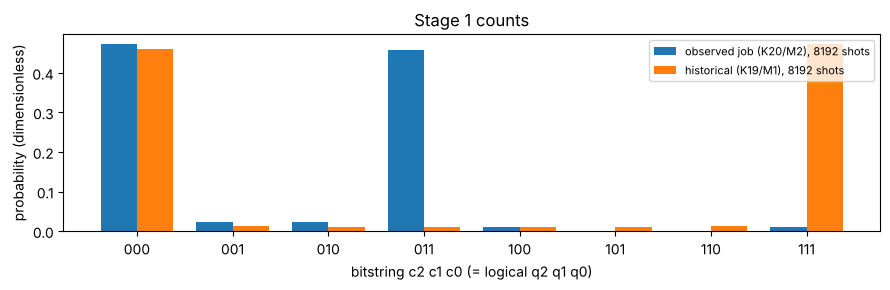

dominant outcomes ['000', '011']: 0.932 of shots; outside them: 0.068
P(000)+P(111): observed 0.4834 vs historical 0.9336; P(q2=1) observed 0.021
TVD of observed counts to each simulated hypothesis: {'faithful': 0.5033, 'misrouted': 0.0369, 'omitted': 0.0369}

diagnostic jobs 5/20, shots 6656/10000, max qubits 4/4, max depth 6/50
  - local_aer_hypothesis_faithful (shots 1536, qubits [0, 1, 4], depth 6): Local seeded Aer simulation (seed
    20261113, 2% symmetric readout error, no hardware) of the compiled circuit exactly as scheduled; TVD to
    observed execution_counts = 0.503.
  - local_aer_hypothesis_misrouted (shots 1536, qubits [0, 1, 2, 4], depth 6): Local seeded Aer simulation
    (seed 20261113, 2% symmetric readout error, no hardware) of the compiled circuit with the suspect CX
    replaced by the stale profile endpoints; TVD to observed execution_counts = 0.037.
  - local_aer_hypothesis_omitted (shots 1536, qubits [0, 1, 4], depth 5): Local seeded Aer simulation (seed
    2

In [6]:
obs, hist = J(S1, 'execution_counts.json')['counts'], J(S1, 'historical_counts.json')['counts']
keys = [format(i, '03b') for i in range(8)]
tot_o, tot_h = sum(obs.values()), sum(hist.values())
p = s1['estimated_parameters']
fig, ax = plt.subplots(figsize=(9, 3)); w = 0.38
ax.bar(np.arange(8) - w/2, [obs.get(k, 0)/tot_o for k in keys], w, label=f'observed job ({log["calibration_epoch"]}/{log["mapping_id"]}), {tot_o} shots')
ax.bar(np.arange(8) + w/2, [hist.get(k, 0)/tot_h for k in keys], w,
       label=f'historical ({J(S1, "historical_counts.json")["calibration_epoch"]}/{J(S1, "historical_counts.json")["mapping_id"]}), {tot_h} shots')
ax.set_xticks(range(8)); ax.set_xticklabels(keys); ax.set_xlabel('bitstring c2 c1 c0 (= logical q2 q1 q0)')
ax.set_ylabel('probability (dimensionless)'); ax.legend(fontsize=8); ax.set_title('Stage 1 counts'); plt.tight_layout(); plt.show()
top2 = sorted(obs, key=obs.get, reverse=True)[:2]
print(f"dominant outcomes {top2}: {sum(obs[k] for k in top2)/tot_o:.3f} of shots; outside them: {1 - sum(obs[k] for k in top2)/tot_o:.3f}")
print(f"P(000)+P(111): observed {p['observed_p_ghz_000_or_111_fraction']} vs historical {p['historical_p_ghz_000_or_111_fraction']}; "
      f"P(q2=1) observed {p['observed_p_logical_q2_one_fraction']}")
print('TVD of observed counts to each simulated hypothesis:',
      {k.replace('tvd_observed_vs_', '').replace('_model_probability', ''): v for k, v in p.items() if k.startswith('tvd_')})
budget = J(S1, 'diagnostic_budget.json'); d = s1['diagnostic_evidence']
print(f"\ndiagnostic jobs {len(d)}/{budget['maximum_diagnostic_jobs']}, shots {sum(x['shots'] for x in d)}/"
      f"{budget['maximum_total_diagnostic_shots']}, max qubits {max(len(x['qubits']) for x in d)}/{budget['maximum_qubits_per_probe']}, "
      f"max depth {max(x['depth'] for x in d)}/{budget['maximum_circuit_depth']}")
for x in d:
    print(textwrap.fill(f"{x['job_id']} (shots {x['shots']}, qubits {x['qubits']}, depth {x['depth']}): {x['claim']}",
                        width=110, initial_indent='  - ', subsequent_indent='    '))

**Reading.** q0 and q1 stay correlated, but logical q2 (physical 4) almost never reads 1, so the second CX never
acted on physical 4. The "misrouted" and "omitted" hypotheses fit the counts equally well, because physical 2 is
never measured. The realized edge is therefore inferred from the binding's provenance (§1.3), and the
edge-isolation probe above is what would discriminate the two on the real stack.

## 1.5 Verdict, affected operation and resources

In [7]:
say('verdict (M1)', f"{s1['verdict']}, confidence {s1['confidence']}")
items('affected logical operation (M6)', s1['affected_logical_operations'])
items('expected physical resources (M7)', s1['expected_physical_resources'])
items('suspected realized resources (M8)', s1['suspected_realized_resources'])
print(); say('root cause', s1['root_cause'])

verdict (M1): INTEGRITY_VIOLATION, confidence 0.95
affected logical operation (M6):
  - cx_1_2 (CX q1->q2; schedule op ent_73; binding bind_73)
expected physical resources (M7):
  - physical qubits (1,4): CX control 1 -> target 4 (node_b->node_e)
  - K20 profile cp_026 on control channel u15
suspected realized resources (M8):
  - physical qubits (1,2): CX control 1 -> target 2 (node_b->node_c)
  - stale K19 profile cp_017 on control channel u12 (bundle cb_73c, device epoch D19)

root cause: OBSERVATIONS: compiler, mapping and schedule are mutually consistent and place cx_1_2 on CX 1->4.
    Control binding bind_73 for ent_73 references K19 profile cp_017 on channel u12 (created
    2026-05-02T11:44:08Z, before the mapping change at 2026-08-14T09:00:00Z), whose endpoints are
    node_b->node_c = physical (1,2). The current K20 profile for (1,4) is cp_026/u15 and is unbound. Counts
    show logical q2 (physical 4) never flips. CONCLUSION (confidence ~0.97 for the violation and its contro

## 1.6 Incidental anomalies (rejected)

In [8]:
items('incidental anomalies (M9)', s1['incidental_anomalies'])
print(); say('measurement layer', s1['layer_assessments']['measurement'])

incidental anomalies (M9):
  - node_d (physical 3) relative_gate_quality 0.86: physical 3 is not used by the mapping, schedule, any
    binding or the suspected realized edge, so it cannot affect this job.
  - node_f (physical 5) readout_error 0.08: physical 5 is not used by the mapping, schedule, any binding or
    the suspected realized edge, so it cannot affect this job.
  - bind_41 channel changed u3 (cp_014, K19) -> u7 (cp_021, K20) for the same edge (0, 1): a legitimate
    recalibration/channel renumbering; its edge is correct and q0/q1 correlation is intact.
  - Mapping change M1->M2 (ticket maint_2048) is documented and applied consistently in compiler, schedule and
    log; it is the trigger that exposed the stale binding, not itself a fault.
  - CX durations differ (ent_41=176 ns, ent_73=192 ns); different edges/calibrations legitimately have
    different pulse lengths and the schedule has no overlaps, so duration alone is not evidence of the fault.
  - calibration_previous

## 1.7 Repair and repair validation

In [9]:
say('proposed repair (M11)', s1['proposed_repair']); print()
say('repair validation (M12)', s1['repair_validation'])
print('\nartifact citations:'); evidence(s1['artifact_evidence'])

proposed repair (M11): Regenerate binding bind_73 for K20: bind ent_73 to profile cp_026 on channel u15
    (node_b->node_e = physical 1->4); invalidate and rebuild bundle cb_73c; remove cp_017/u12 from the D20
    manifest and re-issue cm_20_0814. Add pre-execution gates: (a) every binding.calibration_epoch equals
    execution_log.calibration_epoch and the current calibration epoch; (b) every bound profile exists in the
    current calibration; (c) the profile endpoint_refs, resolved via endpoint_registry and kept in [control,
    target] order, equal the scheduled physical_qubits; (d) any mapping change triggers regeneration of all
    bindings touching moved qubits.

repair validation (M12): (1) Static: re-run the binding gates above on the re-issued manifest; all bindings
    must be K20 and endpoint-matched. (2) Edge-isolation probe on physical [1,4,2] (in diagnostic_evidence,
    validated by diagnostic_client): X(1); repaired CX(1->4); measure 1,4,2. Expect 4 flipped and 2 unch

# Stage 2: cross-layer forensics (32-qubit workload)

**Question.** Did the workload's target interaction execute as intended? The solver checks every layer.
Compiler, mapping, schedule and runtime turn out consistent; the fault lies in the provenance chain
device design → device model → control calibration.

## 2.1 Circuit, compilation, mapping and runtime

In [10]:
ch = J(S2, 'challenge.json')['circuit']
print({k: ch[k] for k in ('physical_qubits', 'two_qubit_gates', 'rounds', 'target_operation_id', 'intended_target_instruction_index',
                          'target_instruction_index', 'target_physical_edge')})
for k in ('compiler', 'mapping', 'runtime', 'scheduling'):
    print(); say(k, s2['layer_assessments'][k])
print('\nruntime evidence:'); evidence(s2['runtime_evidence'])

{'physical_qubits': 32, 'two_qubit_gates': 372, 'rounds': 24, 'target_operation_id': 'op_00694', 'intended_target_instruction_index': 2346, 'target_instruction_index': 694, 'target_physical_edge': [1, 4]}

compiler: CONSISTENT. Intended and compiled circuits both have 4212/4212 instructions; the compiled order is a
    reordering of commuting operations, and per-qubit (DAG) gate sequences, names and parameters are
    identical; off-basis gates: none. Target op_00694: intended index 2346 rzz[1, 4](1.5707963267948966) vs
    compiled index 694 rzz[1, 4](1.5707963267948966): identical. The compiled circuit requests exactly
    RZZ(pi/2) on the target edge; the compiler is not the fault boundary.

mapping: CONSISTENT. M21 is the identity layout on 32 qubits; op_00694 maps logical [1, 4] -> physical [1, 4],
    a supported edge of backend-21 (31 edges, a path 0-1-4-2-3-5-...-31).

runtime: CONSISTENT. Runtime synthetic-job-0021 used device revision D21, geometry fingerprint
    74a51d718cc

## 2.2 Device design and device model provenance

Every fingerprint is resolved to a revision through `provenance_registry.json`, and the creation and validity
times are put on one timeline.

In [11]:
reg = J(S2, 'provenance_registry.json'); fp2rev = {r['geometry_fingerprint']: r['revision'] for r in reg['revisions']}
des, mod, cal, rt, loc = (J(S2, n) for n in ('device_design.json', 'device_model.json', 'control_calibration.json',
                                              'simulated_runtime_snapshot.json', 'local_subsystem.json'))
rows = [('runtime ' + rt['artifact_id'], fp2rev.get(rt['geometry_fingerprint']), '-', rt['execution_timestamp']),
        ('backend', fp2rev.get(J(S2, 'backend_snapshot.json')['geometry_fingerprint']), '-', '-'),
        ('design ' + des['artifact_id'], fp2rev.get(des['geometry_fingerprint']), des['local_region']['coupling_proxy_MHz'], '-'),
        ('model ' + mod['artifact_id'], fp2rev.get(mod['source_geometry_fingerprint']), mod['coupling_proxy_MHz'], mod['created_at'])]
print(f"{'record':24s} {'geometry revision':18s} {'coupling g (MHz)':17s} created/executed")
for r_ in rows: print(f"{r_[0]:24s} {str(r_[1]):18s} {str(r_[2]):17s} {r_[3]}")
print(f"\ncalibration {cal['artifact_id']} ({cal['calibration_epoch']}) model_ref = {cal['model_ref']}; "
      f"local_subsystem {loc['artifact_id']}: design_ref = {loc['design_ref']}, model_ref = {loc['model_ref']}")
ev = sorted([(r['timestamp'], f"revision {r['revision']} registered") for r in reg['revisions']] +
            [(mod['created_at'], f"{mod['artifact_id']} created"), (rt['execution_timestamp'], f"job {rt['simulated_job_id']} executed")])
print('timeline:'); [print(f'  {a}  {b}') for a, b in ev]
print(); say('device design (M4)', s2['layer_assessments']['device_design'])
print(); say('device model (M5)', s2['layer_assessments']['device_model'])
print('\ndevice-design evidence:'); evidence(s2['device_design_evidence'])
print('device-model evidence:'); evidence(s2['device_model_evidence'])

record                   geometry revision  coupling g (MHz)  created/executed
runtime runtime-21       D21                -                 2026-08-15T12:00:00Z
backend                  D21                -                 -
design design-21         D21                18.0              -
model model-20           D20                16.0              2026-07-01T09:00:00Z

calibration cal-21 (K21) model_ref = model-20; local_subsystem local-14: design_ref = design-21, model_ref = model-20
timeline:
  2026-07-01T08:00:00Z  revision D20 registered
  2026-07-01T09:00:00Z  model-20 created
  2026-08-15T08:00:00Z  revision D21 registered
  2026-08-15T12:00:00Z  job synthetic-job-0021 executed

device design (M4): CURRENT AND CONSISTENT. design-21 is revision D21, fingerprint 74a51d718cc3..., which the
    provenance registry assigns to D21 (2026-08-15T08:00:00Z) and which equals the runtime/backend
    fingerprint. Local region [1, 4] (components ['geom-Q1', 'geom-Q4'], coupler geom-C14 capac

## 2.3 Coupling/rate physical consequence

Under the supplied reduced assumption ω = 2π·g/1000 rad/ns, the calibrated pulse realizes an angle ω·t. The
characterization probes measure cos(n·ω·t). Because n is an integer, g and k·(1000/t) ± g cannot be
distinguished, so the left plot marks every alias. The aliases are rejected only on physical grounds: they lie
far from both supplied proxies.

control: PROPAGATES THE STALE MODEL. cal-21 (epoch K21, channel u14, edge [1, 4]) has model_ref model-20; its
    nominal_rate 0.10053096491487339 rad/ns = 2*pi*16.0/1000 (the D20 coupling) and pulse_duration 15.625 ns =
    target_angle 1.5707963267948966 / nominal_rate (exact). Given its declared input the calibration
    arithmetic is correct; its defect is that it carries no source-geometry fingerprint and was not checked
    against the D21 runtime, so it inherited the stale rate. Channel/edge binding is consistent: manifest
    control-21, calibration and verification metadata all use u14 on [1, 4]; characterization control_ref
    control-21 shows the probes used this same pulse.

  coupling_design_MHz                                  18
  coupling_model_MHz                                   16
  coupling_error_MHz                                   2
  nominal_rate_model_rad_per_ns                        0.100531
  realized_rate_design_rad_per_ns                      0.113097
  

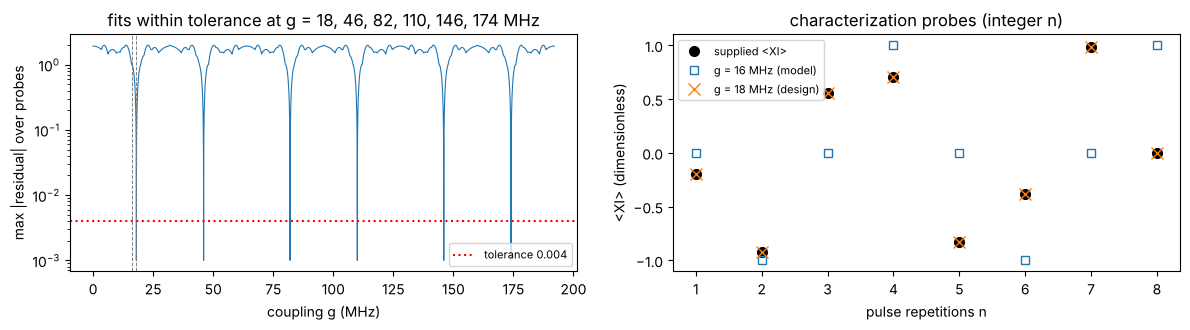

max residual: model g 1.0010 | design g 0.0010 | tolerance 0.004
verification <X>: observed -0.193199 | predicted intended 0.000000 | predicted realized -0.193199 | inverted coupling 18.0000 MHz


In [12]:
p2 = s2['estimated_parameters']; say('control', s2['layer_assessments']['control']); print()
for k in ('coupling_design_MHz', 'coupling_model_MHz', 'coupling_error_MHz', 'nominal_rate_model_rad_per_ns', 'realized_rate_design_rad_per_ns',
          'rate_error_rad_per_ns', 'pulse_duration_ns', 'intended_angle_rad', 'realized_angle_rad', 'over_rotation_rad', 'over_rotation_deg',
          'over_rotation_ratio', 'rzz_process_fidelity_vs_intended_dimensionless', 'coupling_fit_minimax_MHz', 'coupling_fit_window_low_MHz',
          'coupling_fit_window_high_MHz', 'coupling_alias_period_MHz', 'ej_from_design_lj_Q1_GHz', 'ej_model_Q1_GHz', 'ej_model_Q4_GHz'):
    if k in p2: print(f'  {k:52s} {p2[k]:.6g}')
char = J(S2, 'characterization.json'); n = np.array([q['repetitions'] for q in char['probes']]); y = np.array([q['expectation'] for q in char['probes']])
t = p2['pulse_duration_ns']; tol = char['absolute_tolerance']; rate = lambda g: 2 * math.pi * g / 1000
gm, gd = p2['coupling_model_MHz'], p2['coupling_design_MHz']
g = np.arange(0.0, 3 * p2['coupling_alias_period_MHz'], 0.002)
res = np.max(np.abs(np.cos(np.outer(g, n) * rate(1) * t) - y), axis=1)
alias = [round(float(x), 1) for x in g[res <= tol]]; alias = sorted({a for a in alias})
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].semilogy(g, res, lw=0.8); ax[0].axhline(tol, color='r', ls=':', label=f'tolerance {tol}')
for x in (gm, gd): ax[0].axvline(x, color='grey', ls='--', lw=0.7)
ax[0].set_xlabel('coupling g (MHz)'); ax[0].set_ylabel('max |residual| over probes'); ax[0].legend(fontsize=8)
ax[0].set_title('fits within tolerance at g = ' + ', '.join(f'{a:g}' for a in sorted({round(a) for a in alias})) + ' MHz')
ax[1].plot(n, y, 'ko', ms=7, label='supplied <XI>')
ax[1].plot(n, np.cos(n * rate(gm) * t), 's', mfc='none', label=f'g = {gm:g} MHz (model)')
ax[1].plot(n, np.cos(n * rate(gd) * t), 'x', ms=9, label=f'g = {gd:g} MHz (design)')
ax[1].set_xlabel('pulse repetitions n'); ax[1].set_ylabel('<XI> (dimensionless)'); ax[1].legend(fontsize=8)
ax[1].set_title('characterization probes (integer n)'); plt.tight_layout(); plt.show()
print(f"max residual: model g {np.max(np.abs(np.cos(n*rate(gm)*t)-y)):.4f} | design g {np.max(np.abs(np.cos(n*rate(gd)*t)-y)):.4f} | tolerance {tol}")
print(f"verification <X>: observed {p2['verification_X_observed_expectation']:.6f} | predicted intended "
      f"{p2['verification_X_predicted_intended_expectation']:.6f} | predicted realized {p2['verification_X_predicted_realized_expectation']:.6f} "
      f"| inverted coupling {p2['verification_inferred_coupling_MHz']:.4f} MHz")

## 2.4 Structured simulation of the 32-qubit workload

Values come from `solve.py`'s Aer `matrix_product_state` runs. It runs at bond limits 128, 256 and 512 with
threshold 1e-10, plus bond 256 at 1e-12, using the seed from `simulation_config.json`. It requests selected
observables only, never the statevector. Global parity cannot see the fault; local observables on the target
edge can.

In [13]:
obs_names = sorted(k[len('mps_workload_'):-len('_intended_expectation')] for k in p2
                   if k.startswith('mps_workload_') and k.endswith('_intended_expectation'))
print(f"{'observable':22s} {'intended':>10s} {'realized':>10s}")
for o in obs_names:
    i_, r_ = p2.get(f'mps_workload_{o}_intended_expectation'), p2.get(f'mps_workload_{o}_realized_expectation')
    print(f"{o:22s} {i_ if i_ is not None else '':>10} {r_ if r_ is not None else '':>10}")
print(f"\nparity with all RZ/RZZ angles randomized: {p2.get('mps_workload_total_parity_random_angles_expectation')}")
print(f"max observable change across bond/threshold settings: {p2['mps_max_observable_delta_across_settings_expectation']:.2e}; "
      f"max bond dimension reached: {p2['mps_max_bond_dimension_reached_count']:.0f}")
print(f"verification circuit <X>: intended {p2['mps_verification_X_intended_expectation']}, realized {p2['mps_verification_X_realized_expectation']}")
print('\nsimulation evidence:'); evidence(s2['simulation_evidence'])

observable               intended   realized
Y1Y4                      0.02984   0.014199
Z1                       0.206961   0.078474
Z1Z4                     0.718743   0.675939
Z4                       0.381431    0.25821
total_parity                  1.0        1.0

parity with all RZ/RZZ angles randomized: 1.0
max observable change across bond/threshold settings: 7.23e-07; max bond dimension reached: 23
verification circuit <X>: intended -0.0, realized -0.193199

simulation evidence:
  - [simulation_config.json @ recommended_method; convergence_policy] Aer matrix_product_state, seed 20261112;
    settings (bond, threshold) [(128, 1e-10), (256, 1e-10), (512, 1e-10), (256, 1e-12)]; observables via
    save_expectation_value only (no statevector/distribution). Per-setting max |delta| vs (256, 1e-10):
    128_1e-10: 0.0e+00, 256_1e-10: 0.0e+00, 512_1e-10: 0.0e+00, 256_1e-12: 7.2e-07. Max bond dimension reached
    = 23 (< smallest limit 128), so no bond-limit truncation occurred; disc

## 2.5 Root-cause boundary and verdict

In [14]:
say('verdict (M1)', f"{s2['verdict']}, confidence {s2['confidence']}")
say('boundary (M7)', s2['layer_assessments']['root_cause_boundary'])
items('affected logical operations', s2['affected_logical_operations'])
items('expected physical resources', s2['expected_physical_resources'])
items('suspected realized resources', s2['suspected_realized_resources'])
print(); say('root cause', s2['root_cause'])

verdict (M1): INTEGRITY_VIOLATION, confidence 0.95
boundary (M7): PRIMARY: device design design-21 (D21) -> device model model-20 (D20): the model was never
    regenerated after D21 (fingerprint mismatch, g 16.0 vs 18.0 MHz; junction EJ [20.1, 19.8] GHz vs D21 Lj-
    derived 16.35 GHz). PROPAGATION: model-20 -> cal-21 (K21): the calibration correctly derives its pulse
    from its declared model_ref but has no geometry-fingerprint check against the D21 runtime. DOWNSTREAM
    (clean): compiler, mapping, schedule, runtime executed as configured.
affected logical operations:
  - op_00694: RZZ(pi/2) on logical [1, 4] (intended index 2346, compiled index 694, schedule start 1580.0 ns,
    control control-21)
  - verification companion target instruction 65 (same calibration)
expected physical resources:
  - physical edge (1,4) via coupler geom-C14 on channel u14
  - D21 device model (source fingerprint 74a51d718cc3...) with g = 18.0 MHz
  - rate 0.113097 rad/ns; 13.8889 ns pulse for thet

## 2.6 Rejected alternatives and distractors

In [15]:
say('alternatives (M8)', s2['layer_assessments']['alternatives']); print()
say('noise', s2['layer_assessments']['noise']); print()
items('incidental anomalies / distractors', s2['incidental_anomalies'])

alternatives (M8): REJECTED: Index difference intended 2346 vs compiled 694 for op_00694: commuting reorder;
    operation, qubits and angle identical.; compiler: DAG-identical, requests exactly the intended angle;
    mapping: identity layout, supported edge [1, 4]; scheduling: matches compiled circuit; target duration
    equals calibration; wrong control channel/edge: u14 bound to [1, 4] in manifest, calibration,
    characterization and verification metadata; runtime/backend: D21/K21 and fingerprint consistent with
    design; T1/T2 decoherence: the longest probe (8 pulses = 125.0 ns) gives T2 damping 0.99844 on [1, 4], far
    too small for the observed shifts; decay would shrink |<XI>| with n, but |<XI>| reaches 0.982 at n=7, and
    the sign pattern is a coherent rotation; readout error: off-edge outliers only; verification uses no
    readout channel; crosstalk: noise assumptions no_crosstalk=true; characterization is isolated; qubit-
    parameter drift: all 32 design componen

## 2.7 Repair and repair validation

In [16]:
say('proposed repair (M9)', s2['proposed_repair']); print()
say('repair validation (M10)', s2['repair_validation'])
print('\ncontrol evidence:'); evidence(s2['control_evidence'])
print('other artifact citations:'); evidence(s2['artifact_evidence'])
print('diagnostic evidence (local probe replays):')
for x in s2['diagnostic_evidence']:
    print(textwrap.fill(f"{x['job_id']} (shots {x['shots']}, qubits {x['qubits']}, depth {x['depth']}): {x['claim']}",
                        width=110, initial_indent='  - ', subsequent_indent='    '))

proposed repair (M9): (1) Regenerate the reduced device model from the D21 geometry
    (source_geometry_fingerprint 74a51d718cc33d6f422f4ffd3633011bf2890fb066bb200d4afa81e5f6f08c0e), giving
    coupling_proxy_MHz = 18.0 for (1,4); register it as a new artifact and repoint local-14 to it. (2) Issue a
    new calibration epoch (rather than editing cal-21) for channel u14: nominal_rate 0.113097 rad/ns and
    pulse_duration 13.8889 ns, or keep 15.625 ns with amplitude_scale 0.8889 (valid only if rate is linear in
    drive; the model states "Proxy g includes drive scaling", so re-verify). (3) Provenance gate: a
    calibration may be used only if its model's source_geometry_fingerprint equals the runtime/backend
    geometry_fingerprint; a new device revision invalidates models and calibrations derived from earlier
    revisions. (4) Audit control-base for the same dependency.

repair validation (M10): (1) Provenance: model.source_geometry_fingerprint == design == runtime fingerprint
   

# 3. Bonus summary (`extensions/`)

The bonus is optional and reviewed separately. Each directory has its own README containing the source,
assumptions, reproduction command, results and a comparison table against the challenge evidence. This
section only reads their stored `results.json` (regenerate them with the commands in §4).

In [17]:
b1, b2, b3 = (J(E / d, 'results.json') for d in ('device_reconstruction', 'scqubits_model', 'qutip_validation'))
es, cb = b1['electrostatics'], b1['consistency_checks']
print('B1 Quantum Metal - extensions/device_reconstruction/README.md')
print(f"  built {b1['scope']['qubits_built']} + coupler; pads owned by {cb['coupler_pad_owners']}; pads in own pocket {cb['coupler_pads_inside_etched_pocket']}")
print(f"  electrostatics: Cc {es['Cc_fF_range'][0]:.2f}-{es['Cc_fF_range'][1]:.2f} fF, g {es['g_exchange_MHz_range'][0]:.1f}-"
      f"{es['g_exchange_MHz_range'][1]:.1f} MHz over grids {[r['grid_um'] for r in es['runs']]} um (order of magnitude only)")
m = b2['mechanism_test']
print('B2 scqubits - extensions/scqubits_model/README.md')
print(f"  f01 Q1/Q4 {b2['single_transmon']['Q1']['f01_GHz']:.4f}/{b2['single_transmon']['Q4']['f01_GHz']:.4f} GHz; "
      f"static ZZ at design g {b2['coupled']['design21_g18']['hilbertspace']['static_ZZ_MHz']:.3f} MHz")
print(f"  probe residual: linear proxy {m['linear_proxy_max_residual']:.4f}, g^2 law {m['g_squared_scaling_max_residual']:.3f}, "
      f"static ZZ only {m['static_ZZ_only_max_residual']:.3f} (tolerance {m['tolerance']})")
c3, k3 = b3['characterization'], b3['compiled_block']
print('B3 QuTiP - extensions/qutip_validation/README.md')
print(f"  fit g {c3['qutip_minimax_fit_g_MHz']:.4f} MHz, window {c3['fit_window_within_tolerance_MHz']}; compiled block "
      f"{[i['index'] for i in k3['instructions']][:3]}... fidelity {k3['process_fidelity_realized_vs_intended']:.6f}")
print(f"  repair worst probe deviation over fit window {b3['repair']['worst_probe_deviation_over_fit_window']:.4f} "
      f"(passes: {b3['repair']['passes_within_tolerance_over_fit_window']})")

B1 Quantum Metal - extensions/device_reconstruction/README.md
  built [0, 1, 4, 2] + coupler; pads owned by [[1], [4]]; pads in own pocket True
  electrostatics: Cc 0.69-1.18 fF, g 24.3-28.4 MHz over grids [10.0, 6.0, 5.0, 4.0] um (order of magnitude only)
B2 scqubits - extensions/scqubits_model/README.md
  f01 Q1/Q4 6.0793/6.1456 GHz; static ZZ at design g 4.492 MHz
  probe residual: linear proxy 0.0010, g^2 law 1.187, static ZZ only 1.829 (tolerance 0.004)
B3 QuTiP - extensions/qutip_validation/README.md
  fit g 18.0000 MHz, window [17.9965, 18.0055]; compiled block [547, 548, 549]... fidelity 0.990393
  repair worst probe deviation over fit window 0.0034 (passes: True)


# 4. Reproducing everything

From the repository root:

```sh
python -m venv .venv && source .venv/bin/activate
python -m pip install -r requirements-core.txt
python -m pip install matplotlib nbconvert ipykernel          # notebook only
python evaluate.py --submission solve.py --output outputs/result.json
python validate_submission.py outputs/result.json --submission solve.py
jupyter nbconvert --to notebook --execute --inplace outputs/solution.ipynb

# optional bonus (needs requirements-advanced.txt); run B1 before B2
QT_QPA_PLATFORM=offscreen python extensions/device_reconstruction/reconstruct_geometry.py
python extensions/scqubits_model/reconstruct_model.py
python extensions/qutip_validation/validate_dynamics.py
```

This notebook lives in `outputs/` because `validate_submission.py` rejects files outside the released artifact
set, except in `outputs/` and `extensions/`. To run it from a copy outside the repository, set `QEIC_ROOT` to the
repository path.